# Experiment 4: Hill climbing
Steepest-ascent hill climbing on a 1-D landscape and on eight queens, with random restarts.

In [1]:
import json, random
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelmax

TRIALS = 500          # independent trials per measured percentage

## The 1-D landscape, its local maxima, and where hill climbing ends from each start

local maxima at x = [0.52 1.47 2.75 5.28 7.65 8.85 9.95] ; global at 7.65
1-D: 26.2% of 600 grid starts reach the global maximum


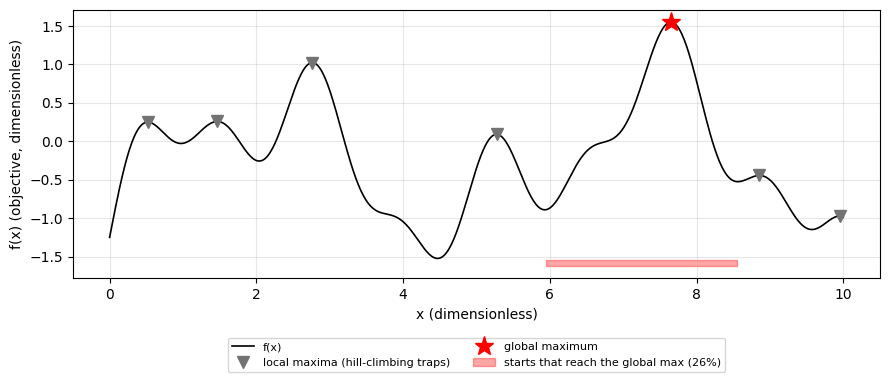

In [2]:
xs = np.linspace(0, 10, 600)
def f(x):
    return np.sin(x) + 0.6*np.sin(2.7*x) + 0.35*np.sin(5.1*x) - 0.05*(x - 5)**2
fx = f(xs)
peaks = argrelmax(fx)[0]
g = peaks[np.argmax(fx[peaks])]

def hill_climb_1d(i):
    """Steepest ascent on the sampled grid: move to the higher neighbour until none is higher."""
    while True:
        nb = [j for j in (i - 1, i + 1) if 0 <= j < xs.size]
        best = max(nb, key=lambda j: fx[j])
        if fx[best] <= fx[i]:
            return i
        i = best

ends = np.array([hill_climb_1d(i) for i in range(xs.size)])
p_global_1d = float(np.mean(ends == g))
print("local maxima at x =", np.round(xs[peaks], 2), "; global at", round(xs[g], 2))
print(f"1-D: {100*p_global_1d:.1f}% of {xs.size} grid starts reach the global maximum")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xs, fx, lw=1.2, color="k", label="f(x)")
loc = [p for p in peaks if p != g]
ax.plot(xs[loc], fx[loc], "v", ms=8, color="0.45", label="local maxima (hill-climbing traps)")
ax.plot(xs[g], fx[g], "*", ms=14, color="r", label="global maximum")
basin = ends == g
ax.fill_between(xs, fx.min() - 0.1, fx.min() - 0.02, where=basin, color="r", alpha=0.35,
                label=f"starts that reach the global max ({100*p_global_1d:.0f}%)")
ax.set(xlabel="x (dimensionless)", ylabel="f(x) (objective, dimensionless)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig4_1_landscape.png", dpi=150); plt.show()

## Eight queens: complete random board, repaired by the best single-queen move

In [3]:
def conflicts(board):                         # from Experiment 2
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i:
                bad += 1
    return bad

def hill_climb(n=8, seed=0):
    """Steepest descent on conflicts. Returns (solved, steps)."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]
    steps = 0
    while True:
        current = conflicts(board)
        if current == 0:
            return True, steps
        best, move = current, None
        for c in range(n):
            old = board[c]
            for row in range(n):
                if row == old: continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, move = v, (c, row)
            board[c] = old
        if move is None:
            return False, steps               # local minimum or plateau: stuck
        board[move[0]] = move[1]; steps += 1

def hill_climb_restarts(n, k, seed):
    for i in range(k):
        if hill_climb(n, seed=seed*1000 + i)[0]:
            return True
    return False

plain = [hill_climb(8, seed=s) for s in range(TRIALS)]
succ = sum(ok for ok, _ in plain)
p = succ / TRIALS
se = np.sqrt(p*(1 - p)/TRIALS)
R = {"trials": TRIALS, "plain_successes": succ, "p": p, "p_stderr": se,
     "mean_steps_success": float(np.mean([s for ok, s in plain if ok])),
     "mean_steps_fail": float(np.mean([s for ok, s in plain if not ok])),
     "landscape_local_maxima_x": [round(float(v), 2) for v in xs[peaks]],
     "landscape_global_x": round(float(xs[g]), 2), "landscape_p_global": p_global_1d}
print(f"plain hill climbing: {succ}/{TRIALS} = {100*p:.1f}% (± {100*se:.1f}% s.e.)")

# second, independent batch of seeds: shows run-to-run sampling variation (viva Q5)
p2 = sum(hill_climb(8, seed=10**6 + s)[0] for s in range(TRIALS)) / TRIALS
R["p_second_batch"] = p2
print(f"second batch, different seeds: {100*p2:.1f}% of {TRIALS}")

plain hill climbing: 68/500 = 13.6% (± 1.5% s.e.)


second batch, different seeds: 14.4% of 500


## Random restarts: measured against 1 - (1 - p)^k

k= 1: measured  13.2% of 500, predicted  13.6%


k= 2: measured  26.2% of 500, predicted  25.4%


k= 5: measured  54.0% of 500, predicted  51.9%


k=10: measured  77.2% of 500, predicted  76.8%


k=20: measured  94.4% of 500, predicted  94.6%
restarts needed for 99%: 32


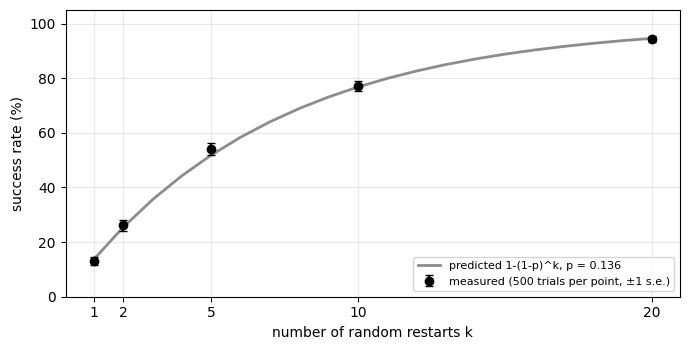

In [4]:
K = [1, 2, 5, 10, 20]
rows = []
for k in K:
    ok = sum(hill_climb_restarts(8, k, seed=5000 + s) for s in range(TRIALS)) / TRIALS
    rows.append(dict(k=k, trials=TRIALS, measured=ok, predicted=1 - (1 - p)**k))
    print(f"k={k:>2}: measured {100*ok:5.1f}% of {TRIALS}, predicted {100*(1-(1-p)**k):5.1f}%")
R["restarts"] = rows
R["k_for_99"] = int(np.ceil(np.log(0.01)/np.log(1 - p)))
print("restarts needed for 99%:", R["k_for_99"])

kk = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(kk, 100*(1 - (1 - p)**kk), "-", color="0.55", lw=2, label=f"predicted 1-(1-p)^k, p = {p:.3f}")
ax.errorbar(K, [100*r["measured"] for r in rows],
            yerr=[100*np.sqrt(r["measured"]*(1 - r["measured"])/TRIALS) for r in rows],
            fmt="o", color="k", capsize=3, label=f"measured ({TRIALS} trials per point, ±1 s.e.)")
ax.set(xlabel="number of random restarts k", ylabel="success rate (%)", ylim=(0, 105), xticks=K)
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figs/fig4_2_restarts.png", dpi=150); plt.show()

In [5]:
json.dump(R, open("results.json", "w"), indent=1)